# Geometry and hydrograph responses: current-release review

This notebook starts stages 1–3 using the saved October release. It does not route, recalibrate, or fit a predictor. Canonical observations are unique `(network, fingerprint)` states compared with that network's base. Alias labels are retained separately. Whole-network geometry is computed from **physical length, width and connectivity only**; model quantities are in a separate diagnostic table.

**Scope remaining:** audit matched local/compound boundaries and physical overlaps before grouped validation. Unit labels here establish stored membership, not independent CV groups. The 15 fully collapsed reference sections remain a separate experiment and are not mixed into these 2,172 local comparisons.

**Interpretation:** every candidate needs a physical interpretation and an individual diagnostic plot. A strong marginal correlation is not mandatory: exposure × branch contrast can be informative when either factor alone is weak. Select within training folds later; this review performs no selection.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/Users/6256481/Code/river-hierarchy')
OUT=Path('/Users/6256481/Code/river-hierarchy/RAPID/outputs/geometry_response_foundation_20261012T120140')
pairs=pd.read_parquet(OUT/'canonical_pairs.parquet')
states=pd.read_parquet(OUT/'canonical_states.parquet')
geo=pd.read_parquet(OUT/'network_geometry.parquet')
zero=pd.read_csv(OUT/'same_sampled_peak_audit.csv',dtype={'example':str})
lobes=pd.read_csv(OUT/'54_lobe_audit.csv',dtype={'example':str})
assert len(pairs)==2172 and len(states)==2187
display(pairs.groupby('example').agg(comparisons=('fingerprint','size'),later=('sampled_peak_shift_minutes',lambda s:(s>0).sum()),same=('sampled_peak_shift_minutes',lambda s:(s==0).sum())))

,comparisons,later,same
example,,,
02,35,17,2
03,40,0,2
05,51,0,0
13,66,3,3
15,262,39,89
21,30,0,0
22,408,49,101
37,396,72,86
41,182,6,7


## Same sampled maximum does not establish identical timing

The output is a 60-second **interval mean**, not an instantaneous sample of the exact crest. Three-point quadratic interpolation gives a sensitivity check only. It assumes a locally smooth, single crest and does not establish a confidence interval or numerical convergence. Broad plateaus, competing lobes, forcing resolution and the native routing clock are separate qualifications. Changing the reporting convention is not evidence of a routing error.

There are 321 pairs with the same sampled maximum time. The following examples retain the raw sampled label and show the interpolated difference separately.

In [ ]:
display(zero[zero.state_id.isin(['S004_unit_5','S011_unit_13','S006_unit_146','S001_unit_19'])][['example','state_id','sampled_shift_minutes','feature_shift_minutes','quadratic_shift_seconds','peak_change_pct']])

,example,state_id,sampled_shift_minutes,feature_shift_minutes,quadratic_shift_seconds,peak_change_pct
0,02,S004_unit_5,0,0.0,-33.213583,-0.048360
1,02,S011_unit_13,0,0.0,-13.194374,0.002229
198,37,S006_unit_146,0,0.0,21.425992,-0.001669
301,54,S001_unit_19,0,-1.0,-37.042892,0.000886


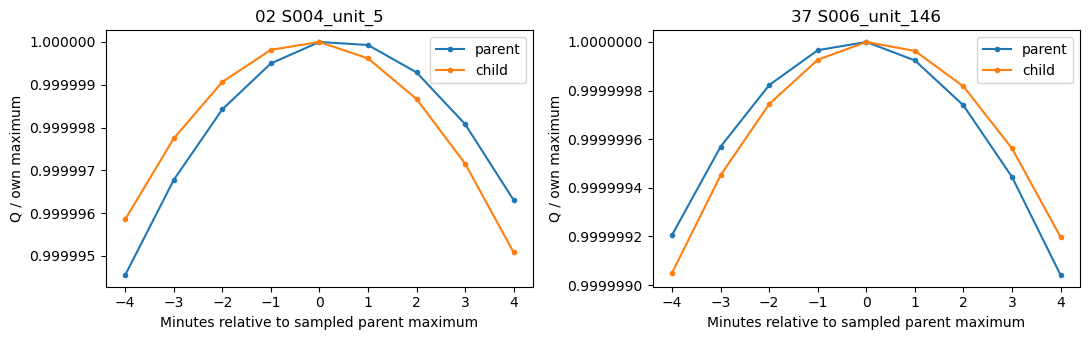

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for ax,(ex,sid) in zip(axes,[('02','S004_unit_5'),('37','S006_unit_146')]):
    child=states[(states.example==ex)&(states.state_id==sid)].iloc[0]
    base=states[(states.example==ex)&states.is_base].iloc[0]
    bw=pd.read_parquet(base.outlet_parquet)
    t0=bw.time_utc.iloc[bw.q_outlet_cms.argmax()]
    for label,row in [('parent',base),('child',child)]:
        w=pd.read_parquet(row.outlet_parquet)
        x=(w.time_utc-t0).dt.total_seconds()/60
        keep=x.abs()<=4
        ax.plot(x[keep],(w.q_outlet_cms/w.q_outlet_cms.max())[keep],'.-',label=label)
    ax.set(title=f'{ex} {sid}',xlabel='Minutes relative to sampled parent maximum',ylabel='Q / own maximum')
    ax.legend(); ax.ticklabel_format(axis='y',style='plain',useOffset=False)
fig.tight_layout(); plt.show()

## Later peaks and unit membership

Classifications below use each base hierarchy and all canonical-state aliases, including island aliases. A positive sampled shift is not automatically attenuation: retain peak-height and shape responses separately. Counts are observations in these networks, not independent experiments.

In [4]:
later=pairs[pairs.sampled_peak_shift_minutes>0]
display(later.groupby(['any_compound_member','any_nested_unit','any_complex_class']).size().rename('comparisons').to_frame())
display(later[~later.any_compound_member][['example','state_id','sampled_peak_shift_minutes','peak_total_change_pct','unit_ids','families']])
print('Later sampled peaks:',len(later),'; lower total peak:',int((later.peak_total_change_pct<0).sum()))

comparisons
any_compound_member any_nested_unit any_complex_class             
False               False           False                        9
True                False           True                        69
                    True            True                       132

,example,state_id,sampled_peak_shift_minutes,peak_total_change_pct,unit_ids,families
12,02,S013_unit_20,4.0,-0.013440,20,"indep,island"
318,15,S127_unit_205,6.0,0.495960,205,"indep,island"
532,22,S049_unit_9,5.0,0.000563,9,"indep,island"
699,22,S216_unit_10,4.0,0.070798,10,"indep,island"
1571,46,S009_unit_29,1.0,-0.009220,29,"indep,island"
1574,46,S012_unit_95,1.0,0.042339,95,"indep,island"
1577,46,S015_unit_9,2.0,-0.002285,9,"indep,island"
1606,46,S044_unit_173,4.0,0.032966,173,"indep,island"
1607,46,S045_unit_25,3.0,0.030984,25,"indep,island"


Later sampled peaks: 210 ; lower total peak: 183


## Network 54: keep centre calibration and compare all three clocks

The production operator picks the two highest qualifying lobes with its reviewed separation rule. The audit reproduces that operator and orders the lobes in time. For every pair,
$$\Delta T_{centre}=\frac{\Delta T_{left}+\Delta T_{right}}2.$$
This is an exact identity; the three clocks are complementary descriptions but not independent targets. We also retain lobe heights and peak separation. All 81 children retain two qualifying lobes; the centre reproduces the saved calibration feature exactly. The midpoint is a timing feature, not necessarily a discharge maximum.

In [ ]:
display(lobes[lobes.state_id.isin(['S001_unit_19','S066_unit_4','CB004_bubble_16','island_54_033','S027_unit_2','S036_unit_52'])][['state_id','left_shift_minutes','center_shift_minutes','right_shift_minutes','sampled_peak_shift_minutes','left_change_pct','right_change_pct']])

,state_id,left_shift_minutes,center_shift_minutes,right_shift_minutes,sampled_peak_shift_minutes,left_change_pct,right_change_pct
0,S001_unit_19,-2.0,-1.0,0.0,0.0,0.001567,0.000886
26,S027_unit_2,-6.0,-2.5,1.0,1.0,-0.085927,-0.091795
35,S036_unit_52,2.0,0.5,-1.0,-1.0,-0.002617,-0.001555
65,S066_unit_4,-40.0,-28.5,-17.0,-17.0,0.406484,0.197215
69,CB004_bubble_16,-56.0,-41.5,-27.0,-27.0,0.417355,0.202514
78,island_54_033,3.0,-10.0,-23.0,-23.0,0.284257,0.173671


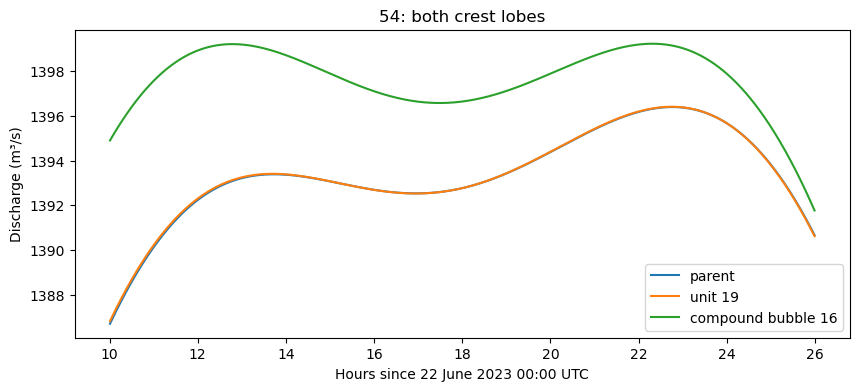

In [6]:
fig,ax=plt.subplots(figsize=(10,4))
base=states[(states.example=='54')&states.is_base].iloc[0]
for sid,label in [('S000_base','parent'),('S001_unit_19','unit 19'),('CB004_bubble_16','compound bubble 16')]:
    row=states[(states.example=='54')&(states.state_id==sid)].iloc[0]
    w=pd.read_parquet(row.outlet_parquet)
    hours=(w.time_utc-pd.Timestamp('2023-06-22',tz='UTC')).dt.total_seconds()/3600
    keep=(hours>=10)&(hours<=26)
    ax.plot(hours[keep],w.q_outlet_cms[keep],label=label)
ax.set(xlabel='Hours since 22 June 2023 00:00 UTC',ylabel='Discharge (m³/s)',title='54: both crest lobes');ax.legend();plt.show()

## Response contract and baseline issue

Use **timing, height, duration and shape as separate responses**. Peak attenuation does not mathematically imply a later peak. Redistribution among routes, dispersion and lobe competition can affect both.

For a reviewed baseline $B(t)$ and event window, define $q(t)=Q(t)-B(t)$, $V=\int qdt$, $\mu=\int tqdt/V$, $\sigma_t^2=\int(t-\mu)^2qdt/V$, and $t_a$ by $\int^{t_a}qdt=aV$. The median $t_{0.5}$ is generally different from the centroid $\mu$. Prefer changes in $\mu$, $\sigma_t$, and $t_{0.9}-t_{0.1}$ alongside peak timing and height; compare $t_{0.75}-t_{0.25}$ as a less tail-sensitive alternative.

For crest widths, use the crossings around a specified lobe of **its own** peak-excess fraction. A connected width at half height differs from the central 50% volume duration. For multimodal events, report lobe widths and total threshold-exceedance duration as different quantities.

**Do not subtract the initial flow and clip.** Initial and final levels differ in current records (54 base: about 279.47 and 772.98 m³/s). Such clipping would invent an event-excess distribution. The response catalogue therefore marks volume/shape targets as baseline-pending. The new response utility requires an explicit baseline and integrates interval means conservatively, including within-interval temporal variance.

Literature anchors: [USGS centroid/recession definitions](https://www.usgs.gov/publications/estimating-basin-lagtime-and-hydrograph-timing-indexes-used-characterize-stormflows), [peak time, height, volume and widths at fractions of peak](https://nc.water.usgs.gov/reports/wri034108/), and [volume-median and interquartile timing](https://pubs.usgs.gov/publication/sir20235064G/full). The last source concerns annual hydrographs; event-excess versions here are an explicit adaptation. The proposed standardized shape distance and asymmetry measure are project definitions, not claims of a uniquely standard hydrograph metric.

In [7]:
display(pd.read_csv(OUT/'response_definitions.csv'))
sys.path.insert(0,str(ROOT/'RAPID/investigations/geometry_response_foundation_20261012'))
from responses import analytic_checks
analytic_checks()
print('Analytic response checks passed')

,name,equation,dimension,status,interpretation,source_key
0,sampled_peak_shift,Tc-Tp,time,computed,Largest 60-second interval-mean Q; tie and lob...,project operator
1,reviewed_feature_shift,Fc-Fp,time,computed,Production crest definition; 54 uses ordered t...,project operator
2,54_left_right_center,"delta left, delta right, (delta left+delta rig...",time,computed,Retain centre calibration; record both lobe ti...,project operator
3,total_peak_change_pct,100*(Qc_max/Qp_max-1),dimensionless,computed,Positive means amplification; negative means l...,peak_width
4,relative_timing,100*(Fc-Fp)/(Fp-Fi),dimensionless,definition,Conditional on known parent and inlet feature;...,project convention
5,peak_excess_change_pct,100*(qc_max/qp_max-1),dimensionless,baseline_pending,q=Q-B using reviewed event baseline. Separate ...,peak_width
6,centroid_shift,mu_c-mu_p; mu=integral(t*q)/V,time,baseline_pending,"Centre of mass of event excess, not maximum or...",centroid
7,volume_median_shift,t50_c-t50_p; integral_to_t50(q)=V/2,time,baseline_pending,Time half the excess volume has passed. Event-...,volume_quantiles
8,temporal_sd_change,sigma_c-sigma_p; sigma^2=integral((t-mu)^2*q)/V,time,baseline_pending,Spread of event-excess mass through time; also...,moment definition
9,volume_duration80_change,(t90-t10)_c-(t90-t10)_p,time,baseline_pending,Central 80% volume duration; robust complement...,volume_quantiles


Analytic response checks passed


## Shared geometry definitions and comparison scopes

For each physical reach $e$, use length $L_e$ and hydrographic width $w_e$. At a branching node $b$, set $p_{bj}=w_{bj}/\sum_jw_{bj}$. This is a **width-based allocation proxy**, not measured discharge. Let $r_b$ be the conditional probability of reaching $b$ after entering the chosen domain and $r_e=r_b p_{be}$. Shared reaches appear once in edge sums.

Maintain three comparisons: (1) the actual edit within a matched source–sink domain, (2) its containing compound before/after that edit, (3) the whole network before/after. Compute parent value and child-minus-parent change. Keep domain entry exposure, modified length fraction and position separately. A containing compound must not silently stand in for the edited unit. The current numerical table is scope (3); scopes (1–2) require the explicit boundary audit.

Use stable reference scales, e.g. $L_0=\mu_{L,network,parent}$: $\Delta\mu_L/L_0$, $\Delta\sigma_L/L_0$, $\Delta\bar w/L_0$, and differences in already dimensionless measures. Also retain local relative changes when their denominators are meaningful. Whole-network changes are useful, but a small local effect can be diluted. Upstream distance runs from network inlet to domain entry, downstream from domain exit to network outlet, with width-weighted conditioning where needed. Full-network collapse has no external upstream/downstream distance.

Percentage response is dimensionless, but does not make the complete physics dimensionless. Geometry alone cannot supply a time scale. A forcing duration or known parent lag defines conditional response scaling; $cT/L$ and $DT/L^2$ belong in the hydraulic diagnostic model, not the hydrography-only predictor set.

In [13]:
np.sqrt((1-1.5)**2+ (3-1.5)**2)

1.5811388300841898

## Length: what each measure captures

$$\mu_L=\sum_e r_eL_e=\sum_{paths\ k}P_kL_k,\qquad
\sigma_L=\sqrt{\sum_kP_k(L_k-\mu_L)^2},\qquad CV_L=\sigma_L/\mu_L.$$
Route endpoints are the **chosen domain's** source and sink. A simple two-branch parent has two routes; a complete collapse into one route has SD zero. More general simple units may have more than two branches, and a partial compound collapse need not leave a single route.

Example: branch lengths 1 and 3 km, allocated fractions 0.75 and 0.25, give $\mu_L=1.5$ km, $\sigma_L=0.866$ km and $CV_L=0.577$. These are moments of travelled route length, not variation among individual edge lengths.

The old path equivalent length is $L_{eq}=\sum_k W_kL_k/\sum_kW_k$, with $W_k=L_k/\sum_{e\in k}(L_e/w_e)$. In two constant-width parallel branches, that weighting can coincide with width allocation, so $L_{eq}=\mu_L$. In compounds it usually differs: route probabilities multiply local splits, whereas the old path-width sum repeatedly includes shared reaches. The distinction is **weighting**, not an intrinsic link-versus-path distinction.

Shortest/longest routes describe support bounds but ignore allocation. A narrow, little-used long branch can set the maximum. A deterministic shortest path has no separate mean travelled distance; probability-weighted lower/upper route quantiles are better candidates for meaningful tails. Keep extrema as diagnostics.

Skewness $\gamma_L=\sum_kP_k(L_k-\mu_L)^3/\sigma_L^3$ distinguishes a weak long-route tail from a weak short-route tail. It is unstable when SD is almost zero.

At split $b$, branch-length contrast is $s_b^2=\sum_jp_{bj}(L_{bj}+\mu_j-\mu_b)^2$: do the outgoing alternatives have different expected remaining distances to the same sink? Aggregate its mean/SD with visit weights. The identity $\sigma_L^2=\sum_b r_bs_b^2$ means the summed contrast variance is redundant with route variance.

## Width: size, heterogeneity and splitting

$$\bar w=\frac{\sum_e L_ew_e}{\sum_eL_e},\quad
\sigma_w=\sqrt{\frac{\sum_eL_e(w_e-\bar w)^2}{\sum_eL_e}},\quad CV_w=\sigma_w/\bar w.$$
The suggested $\sum L_ew_e/\sum w_e$ has units of length but is a width-weighted **reach length**, not a mean width; it changes if reaches are subdivided.

$$w_H=\frac{\sum_eL_e}{\sum_eL_e/w_e}.$$
For a serial path, this preserves the additive geometric quantity $\sum L/w$ and emphasizes narrow sections. Equal-length sections of widths 10 and 100 m have arithmetic width 55 m and harmonic width 18.18 m. It is not a universal hydraulic resistance: depth, shape and roughness are absent. On a branched graph it is a descriptive aggregate, not a series/parallel equivalent conductance.

Path arithmetic width describes typical width; path harmonic width emphasizes constrictions. Minimum/maximum harmonic path width are sensible additional candidates, but neither equals the most/least probable route. Length-weighted reach quantiles, widest/narrowest effective paths, and local dominance describe different things. Avoid adding their complete-path widths together.

At a split, $d_b=\max p_j$; $N_{2,b}=1/\sum p_j^2$ is the inverse-Simpson effective branch count; $H_b=-\sum p_j\ln p_j$ and $h_b=H_b/\ln k_b$ are entropy and normalized entropy. A balanced two-way split has $N_2=2,h=1$; a 90:10 split has $N_2=1.220,h=0.469$. These are alternative summaries of balance, not independent information at a binary split.

Visit-weighted mean $\bar x=\sum_b r_bx_b/\sum_b r_b$ and SD $\sqrt{\sum_b r_b(x_b-\bar x)^2/\sum_b r_b}$ describe the splits encountered. Expected split count $\sum_b r_b$ must be separate, otherwise normalizing the weights hides repeated splitting.

Split impact $I_b=r_b(1-\sum p_j^2)$ combines exposure and branching balance. For independent choices at that node, $1-\sum p_j^2$ is the probability of selecting different branches. Multiplication by $r_b$ is a proposed exposure weighting, not a literal two-particle network probability. At a fully visited split, 50:50 gives 0.5 and 90:10 gives 0.18. Its mean/SD are useful candidates; its sum can exceed one and equals count times mean. It has no branch-length contrast, so cannot alone predict the response.

The earlier notebook already contains conditional split exposure summaries. Distinguish these from the whole-network fraction reaching the edited domain. Keep the complete-path dominant-width fraction retired for complex compounds.

## Adapting entropic braiding to this problem

[Tejedor et al. (2022)](https://agupubs.onlinelibrary.wiley.com/doi/abs/10.1029/2022GL099681) define eBI using channel fractions at cross-sections: $N_1=\exp(H)$ with natural-log entropy (equivalently $2^H$ with base-2 entropy). It is the number of equally sized channels with the same entropy. Width is used as a discharge-partition proxy.

Our proposed **local entropic effective branch count** applies that transform at bifurcations, then summarizes it using visit-weighted mean/SD. This is an adaptation, not the paper's cross-section eBI. It is now computed for the whole-network scope. For 90:10, $N_1=1.384$ versus inverse-Simpson $N_2=1.220$; the latter discounts small branches more strongly. Compare them as competing descriptors.

Do not interpret $\exp(\sum_b r_bH_b)$ as simultaneous channel count: repeated serial splitting multiplies route alternatives. Keep expected split encounters separate. Actual transect-based eBI could be added if geometric cross-sections are consistently available.

## Topological complexity and redundancy

- Bifurcation count measures opportunities to split; width allocation determines how much those splits matter. Its standalone effect can be weak while its interaction with contrast/exposure is meaningful.
- $E$ = unique physical edges, $V$ = vertices, $C$ = connected components in the underlying undirected graph. Parallel physical channels remain separate edges. Cycle rank is $E-V+C$; it counts independent undirected loops, not directed recirculation.
- Junction excess is $\sum_v\max(outdegree(v)-1,0)$: a two-way split contributes 1, a four-way split contributes 3. On our connected single-sink DAGs it equals cycle rank. If all splits are binary, both equal bifurcation count. Do not fit these as three independent mechanisms.
- Expected bifurcations $\sum_b r_b$ counts encounters along an allocated route. Ten tiny seldom-visited side splits can contribute less than one fully visited split.
- $\ln(1+N_{paths})$ compresses exponential route growth. Serial binary choices add approximately $\ln2$ each. It remains a structural descriptor, not carrying capacity, and does not fix overlap by itself.
- Route entropy $\sum_b r_bH_b$ makes barely used alternatives contribute little. It combines number of encounters and balance; local entropy mean and expected encounters offer a more interpretable separation.

All counts use physical hydrography, not routing cells. Density per unique length has units inverse length and can be multiplied by a reference length for a dimensionless version. Normalization removes units, not every dependence on domain size.

No final feature shortlist yet. Remove exact algebraic duplicates first, assess within-network and pooled relationships, then test families/physically justified interactions in grouped validation. Small marginal correlation alone is not grounds for exclusion.

In [8]:
display(pd.read_csv(OUT/'geometry_dictionary.csv')[['name','family','equation','computed_scope','redundancy_note']])

,name,family,equation,computed_scope,redundancy_note
0,total_length,length,sum_e L_e (unique reaches),whole_network,Audit correlations within and across networks;...
1,area_proxy,width,sum_e L_e*w_e,whole_network,Audit correlations within and across networks;...
2,width_mean,width,sum_e L_e*w_e / sum_e L_e,whole_network,Audit correlations within and across networks;...
3,width_sd,width,sqrt(sum_e L_e*(w_e-width_mean)^2 / sum_e L_e),whole_network,Audit correlations within and across networks;...
4,width_cv,width,width_sd/width_mean,whole_network,Audit correlations within and across networks;...
5,width_harmonic,width,sum_e L_e / sum_e(L_e/w_e),whole_network,Audit correlations within and across networks;...
6,width_p10,width,inverse length-weighted width CDF at 0.1,whole_network,Audit correlations within and across networks;...
7,width_p90,width,inverse length-weighted width CDF at 0.9,whole_network,Audit correlations within and across networks;...
8,bifurcations,topological complexity,count(vertices with out-degree > 1),whole_network,Audit correlations within and across networks;...
9,cycle_rank,topological complexity,E-V+C (undirected multigraph),whole_network,Equals junction excess for connected single-si...


## Hydraulic/model diagnostics are a separate layer

Manning $n$, calibrated celerity, inferred depth, $K_b$, beta and travel-time proxies are excluded from the geometry predictor table. Here $K_b$ is a width/depth ratio, with the active depth policy anchored to BASED reference-section estimates and a depth–width exponent; it is not directly observed planform hydrography. Travel time $\sum L/c$ is model-derived, even though it can explain routed timing well. Saved diffusivity must be interpreted with the diffusion multiplier beta.

Use these values to examine **held-out residuals** later. They may explain conditional model behavior or confounding across networks, but an association is not causal proof: forcing, calibration and geometry vary together. The previous approximately 0.848 result was a historical, hydraulic travel-time diagnostic; this notebook produces no new predictive score.

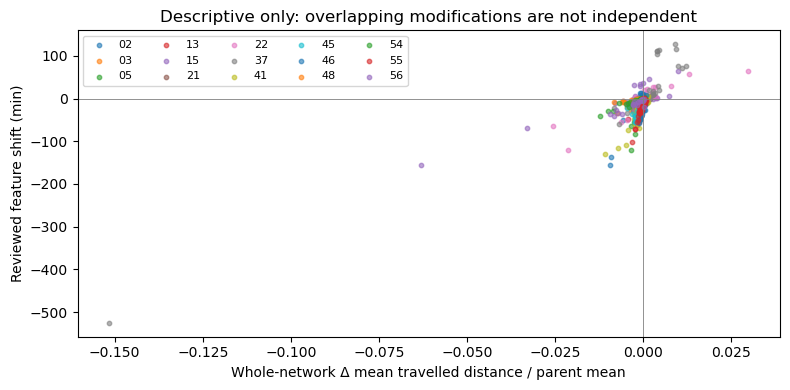

Three algebraic redundancy checks passed across all 2,187 states.


In [9]:
parent=geo.merge(states[['example','fingerprint','is_base']],on=['example','fingerprint'])
parent=parent[parent.is_base].set_index('example')
g=pairs.merge(geo,on=['example','fingerprint'],validate='one_to_one')
g['delta_mean_distance_nd']=(g.route_length_mean-g.example.map(parent.route_length_mean))/g.example.map(parent.route_length_mean)
fig,ax=plt.subplots(figsize=(8,4))
for ex,part in g.groupby('example'):
    ax.scatter(part.delta_mean_distance_nd,part.feature_shift_minutes,s=10,alpha=.6,label=ex)
ax.axhline(0,color='grey',lw=.6);ax.axvline(0,color='grey',lw=.6)
ax.set(xlabel='Whole-network Δ mean travelled distance / parent mean',ylabel='Reviewed feature shift (min)',title='Descriptive only: overlapping modifications are not independent')
ax.legend(ncol=5,fontsize=8);fig.tight_layout();plt.show()
assert np.allclose(geo.branch_length_variance_sum,geo.route_length_sd**2)
assert np.allclose(geo.cycle_rank,geo.junction_excess)
assert np.allclose(geo.split_impact_sum,geo.bifurcations*geo.split_impact_mean)
print('Three algebraic redundancy checks passed across all 2,187 states.')

## Next concrete review

1. Review event windows/baselines on representative hydrographs, including non-returning baselines and 54's two lobes; freeze response definitions and QC rules.
2. Audit matched edit and compound domains against current physical geometry, retain unique modified-edge exposure, and establish alias/nesting/physical-overlap groups. Do not infer independent groups from the family name.
3. Extend the geometry-only table to those scopes, inspect each feature against timing/height/spread separately, and check segmentation/scaling invariance. Shortlist mechanisms, then use grouped inner selection and held-out network evaluation; retain equal-network/group reporting.

No model training, rerouting, calibration changes, or source-result edits were performed.